# Data access without credentials in the browser

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/03-access.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/03-access.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `b9cf4bbae7305442d1a6f336beffdf51efa8c300135f2f8633f31568214846a2`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Data access without credentials in the browser

**Lesson 03 · Original synthetic data · Independent educational project**

## Objectives

Describe discovery, selection and export; distinguish a query plan from a live request.

[Previous](02-grids.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/03-access.ipynb) · [Next](04-validation.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=03-access.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

{'source': 'local synthetic cube', 'variable': 'temperature', 'units': 'K', 'days': 7, 'latitude_bounds': [30, 60], 'longitude_bounds': [-20, 40]}
Local selection: 1,792 of 588,000 bytes


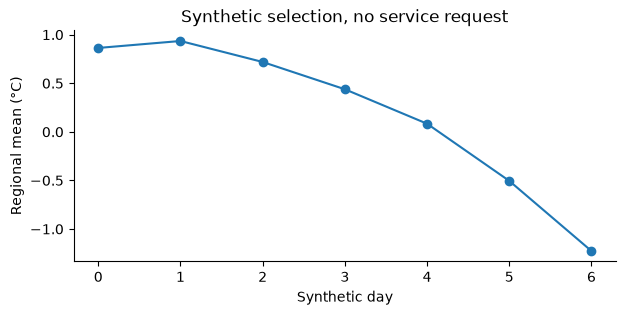

In [2]:
cube = lab.synthetic_cube()
region = (cube["lat"] >= 30) & (cube["lat"] <= 60)
west_east = (cube["lon"] >= -20) & (cube["lon"] <= 40)
subset = cube["temperature"][:7, region, :][:, :, west_east]
plan = {"source": "local synthetic cube", "variable": "temperature", "units": "K", "days": 7,
        "latitude_bounds": [30, 60], "longitude_bounds": [-20, 40]}
assert subset.size > 0
assert subset.nbytes < cube["temperature"].nbytes
print(plan)
print(f"Local selection: {subset.nbytes:,} of {cube['temperature'].nbytes:,} bytes")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(subset.mean(axis=(1, 2)) - 273.15, marker="o")
ax.set(xlabel="Synthetic day", ylabel="Regional mean (°C)", title="Synthetic selection, no service request")
plt.show()

## Exercise

Expand the time range and compute the change in payload size. Draft a selection checklist including grid, units, license and time convention.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

A smaller selection reduces transfer and browser memory. Official catalog-generated requests, account permissions and applicable terms are needed for authentic data. This plan deliberately contains no invented service collection ID.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://polytope.readthedocs.io/en/stable/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).